# EN3150 Assignment 03: EfficientNetB0 fine-tuning (Task 5)

**EfficientNet-B0** (Tan & Le, 2019) uses MBConv blocks (the same inverted-residual idea as MobileNetV2) plus squeeze-and-excitation attention, with its depth, width and resolution chosen by neural architecture search. It uses **SiLU/Swish** activations, `x * sigmoid(x)`, which need an exponential for every value, and sigmoid gates in the squeeze-and-excitation blocks. That is more expensive on microcontrollers than the ReLU family and harder to quantise.

The ImageNet-pretrained model is fine-tuned on GTSRB with **exactly the same recipe as `MobileNetV2`**
(`SOTA/MobileNetV2/src/MobileNetV2_Retrain.ipynb`), and with the same data pipeline as Models A and B, so all four models can be compared
directly.

| Setting | Value |
|---|---|
| Data | `splits/*.csv` (70/15/15), $64 \times 64$ input, `Common/dataset.py` augmentation |
| Normalisation | ImageNet mean / std (the statistics the pretrained weights expect) |
| Batch size / loss | 32 / cross-entropy |
| Stage 1: head warm-up | 3 epochs, backbone frozen, new 43-class head trained with Adam (lr = 1e-3) |
| Stage 2: full fine-tuning | 17 epochs, all layers trainable, Adam (lr = 1e-4) with cosine decay |
| Weights kept | Epoch with the lowest validation loss (same rule as `Common/training.py`) |

The input stays at $64 \times 64$ (no upsampling to 224), keeping the edge-sensor constraint of the assignment.
The head is trained alone first so its random initial gradients do not damage the pretrained features; the whole
network is then unfrozen, because $64 \times 64$ traffic signs are very different from ImageNet photographs.

In [1]:
import copy
import json
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.metrics import confusion_matrix, classification_report

In [2]:
# Fix every random number generator so runs are reproducible
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Make cuDNN use deterministic algorithms (same result on every run)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
# Use the GPU when one is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce GTX 1660 Ti


In [4]:
# Walk up from the notebook's folder to the repository root (the folder that contains .git)
def find_project_root():
    current = Path.cwd().resolve()

    while current != current.parent:
        if (current / ".git").exists():
            return current

        current = current.parent

    raise FileNotFoundError("Could not find project root.")


PROJECT_ROOT = find_project_root()

# Dataset (downloaded by download_data.py), split files and results folders
DATA_ROOT = PROJECT_ROOT / "data" / "gtsrb"
SPLIT_DIR = PROJECT_ROOT / "splits"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "EfficientNetB0"
METRICS_DIR = RESULTS_DIR / "EfficientNetB0"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"

# Make the shared Common package importable
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: E:\UOM resourses\Sem 5\Pattern Recognition\Assignment 3


In [5]:
# Shared code, so every model is prepared, trained and measured the same way
from Common.dataset import create_dataloaders
from Common.training import train_one_epoch, evaluate_epoch
from Common.evaluation import (
    get_predictions,
    calculate_metrics,
    plot_training_curves,
    plot_confusion_matrix,
    print_classification_report,
    total_parameters,
    trainable_parameters,
    estimated_fp32_size_kb,
    save_model_and_get_size,
    measure_inference_time
)
from Common.complexity import count_macs

## 1. Data preparation

Same split files and the same augmentation as `Common/dataset.py`; only the final normalisation changes to the
ImageNet statistics.

In [6]:
# Same augmentation as Common/dataset.py, normalised with the ImageNet statistics the pretrained weights expect
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

imagenet_train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomRotation(degrees=8),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

imagenet_eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

In [7]:
# Fixed 70/15/15 split shared by all models (one row per image: class id and file path)
train_df = pd.read_csv(SPLIT_DIR / "train_split.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_split.csv")
test_df = pd.read_csv(SPLIT_DIR / "test_split.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# Same splits and batch size as Models A and B, with the ImageNet transforms
train_loader, val_loader, test_loader = create_dataloaders(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    data_root=DATA_ROOT,
    batch_size=32,
    num_workers=0,
    train_transform_override=imagenet_train_transform,
    eval_transform_override=imagenet_eval_transform,
    seed=SEED
)

# One batch for the shape check and the smoke test
images, labels = next(iter(train_loader))
print(f"Image batch shape: {tuple(images.shape)}")
assert images.shape[1:] == (3, 64, 64)

Train: 18648
Validation: 3996
Test: 3996


Image batch shape: (32, 3, 64, 64)


## 2. Pretrained EfficientNetB0 with a new 43-class head

The ImageNet classifier `Dropout(0.2) -> Linear(1280, 1000)` is kept except for the final linear layer, which is
replaced by `Linear(1280, 43)`. Pretrained weights are cached in `checkpoints/torch_hub/` (gitignored).

In [8]:
# Cache the downloaded ImageNet weights inside checkpoints/ (gitignored)
torch.hub.set_dir(str(CHECKPOINT_DIR / "torch_hub"))

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
# Replace the 1000-class ImageNet output layer with a new 43-class layer
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 43)
model = model.to(device)

# Parameter counts: pretrained backbone vs the new head
parameters_total = total_parameters(model)
parameters_backbone = sum(p.numel() for p in model.features.parameters())
parameters_head = sum(p.numel() for p in model.classifier.parameters())

print(f"Total parameters:      {parameters_total:,}")
print(f"  Backbone (features): {parameters_backbone:,}")
print(f"  New head (1280->43): {parameters_head:,}")
assert parameters_head == 1280 * 43 + 43

# Multiply-accumulate operations for one 64x64 image
macs = count_macs(model)
print(f"MACs per 64x64 image:  {macs:,}")

# Smoke test: 43 finite scores per image
model.eval()
with torch.inference_mode():
    logits = model(images.to(device))
assert logits.shape == (images.shape[0], 43)
assert torch.isfinite(logits).all()
print(f"Smoke check passed: {tuple(images.shape)} -> {tuple(logits.shape)}")

Total parameters:      4,062,631


  Backbone (features): 4,007,548
  New head (1280->43): 55,083
MACs per 64x64 image:  32,021,632


Smoke check passed: (32, 3, 64, 64) -> (32, 43)


## 3. Two-stage fine-tuning

The loop uses `train_one_epoch` and `evaluate_epoch` from `Common/training.py`, so each epoch is trained and timed
exactly like Models A and B. It is written out here because stage 2 needs a learning-rate scheduler, which
`train_model` does not support. The weights with the lowest validation loss across both stages are kept.

In [9]:
criterion = nn.CrossEntropyLoss()

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "epoch_time": [],
    "stage": []
}

# Weights with the lowest validation loss so far, across both stages
best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())


# Train for some epochs with Common's train/evaluate functions, timing each epoch and recording the history
def run_stage(stage, epochs, optimizer, scheduler=None):
    global best_val_loss, best_weights

    print(f"{stage}: {trainable_parameters(model):,} trainable parameters")

    for epoch in range(epochs):
        start_time = time.perf_counter()

        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_epoch(model, val_loader, criterion, device)

        if device.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start_time

        # Cosine learning-rate decay (stage 2 only)
        if scheduler is not None:
            scheduler.step()

        for key, value in [
            ("train_loss", train_loss),
            ("train_accuracy", train_acc),
            ("val_loss", val_loss),
            ("val_accuracy", val_acc),
            ("epoch_time", elapsed),
            ("stage", stage)
        ]:
            history[key].append(value)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"[{stage}] Epoch {len(history['train_loss']):02d} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Time: {elapsed:.2f}s"
        )

In [10]:
HEAD_EPOCHS = 3
FINE_TUNE_EPOCHS = 17

# Stage 1: backbone frozen, only the new head is trained
for parameter in model.features.parameters():
    parameter.requires_grad = False

head_optimizer = optim.Adam(
    [parameter for parameter in model.parameters() if parameter.requires_grad],
    lr=1e-3
)
run_stage("head", HEAD_EPOCHS, head_optimizer)

# Stage 2: every layer trainable, smaller learning rate with cosine decay
for parameter in model.parameters():
    parameter.requires_grad = True

fine_tune_optimizer = optim.Adam(model.parameters(), lr=1e-4)
fine_tune_scheduler = optim.lr_scheduler.CosineAnnealingLR(fine_tune_optimizer, T_max=FINE_TUNE_EPOCHS)
run_stage("full", FINE_TUNE_EPOCHS, fine_tune_optimizer, fine_tune_scheduler)

# Test with the best weights
model.load_state_dict(best_weights)
best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"Restored weights from epoch {best_epoch} (validation loss {best_val_loss:.4f})")

METRICS_DIR.mkdir(parents=True, exist_ok=True)
with (METRICS_DIR / "efficientnetb0_history.json").open("w", encoding="utf-8") as history_file:
    json.dump(history, history_file, indent=2)

head: 55,083 trainable parameters


[head] Epoch 01 | Train Loss: 2.1247 | Train Acc: 0.3951 | Val Loss: 1.6967 | Val Acc: 0.4990 | Time: 46.63s


[head] Epoch 02 | Train Loss: 1.6808 | Train Acc: 0.4881 | Val Loss: 1.5358 | Val Acc: 0.5293 | Time: 51.25s


[head] Epoch 03 | Train Loss: 1.5889 | Train Acc: 0.5128 | Val Loss: 1.4608 | Val Acc: 0.5563 | Time: 48.40s
full: 4,062,631 trainable parameters


[full] Epoch 04 | Train Loss: 1.0089 | Train Acc: 0.6742 | Val Loss: 0.4486 | Val Acc: 0.8564 | Time: 69.94s


...

[full] Epoch 16 | Train Loss: 0.0248 | Train Acc: 0.9927 | Val Loss: 0.0035 | Val Acc: 0.9985 | Time: 69.88s


[full] Epoch 17 | Train Loss: 0.0209 | Train Acc: 0.9933 | Val Loss: 0.0028 | Val Acc: 0.9990 | Time: 70.21s


[full] Epoch 18 | Train Loss: 0.0209 | Train Acc: 0.9937 | Val Loss: 0.0029 | Val Acc: 0.9990 | Time: 70.85s


[full] Epoch 19 | Train Loss: 0.0192 | Train Acc: 0.9935 | Val Loss: 0.0022 | Val Acc: 0.9992 | Time: 70.10s


[full] Epoch 20 | Train Loss: 0.0173 | Train Acc: 0.9951 | Val Loss: 0.0028 | Val Acc: 0.9992 | Time: 74.86s
Restored weights from epoch 19 (validation loss 0.0022)


## 4. Evaluation

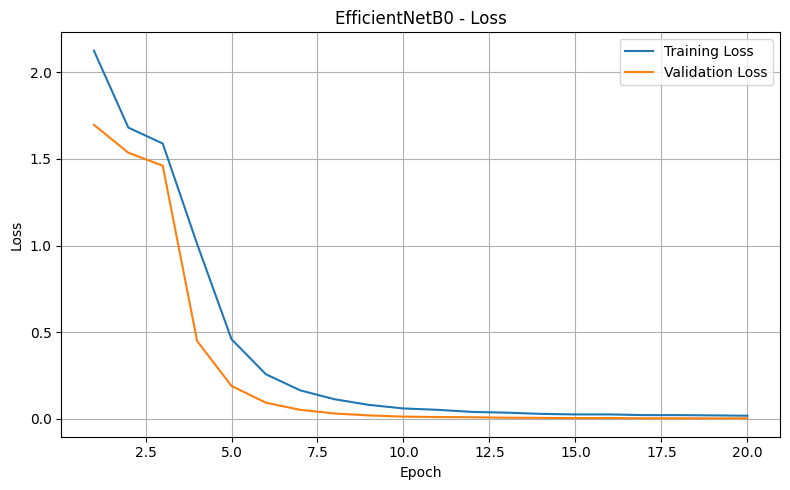

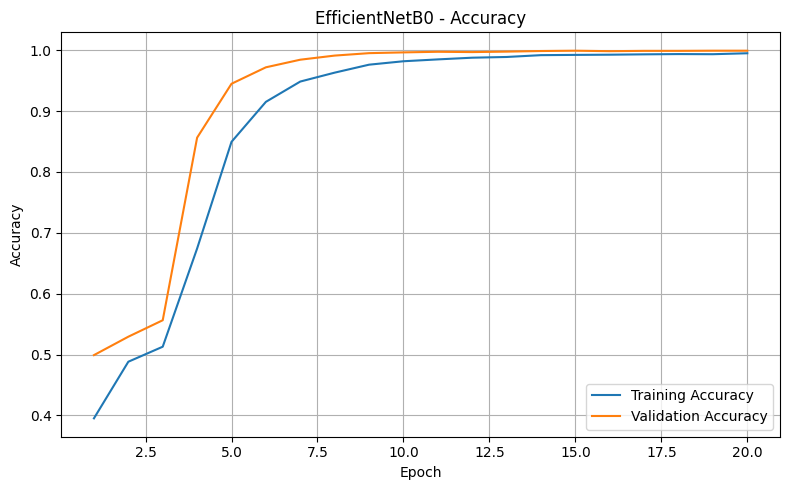

In [11]:
# Training vs validation loss and accuracy curves (saved as PNG)
plot_training_curves(
    history=history,
    model_name="EfficientNetB0",
    save_dir=FIGURES_DIR
)

{'Test Accuracy': 0.9982482482482482, 'Macro Precision': 0.9987282855253404, 'Macro Recall': 0.9991178954477634}


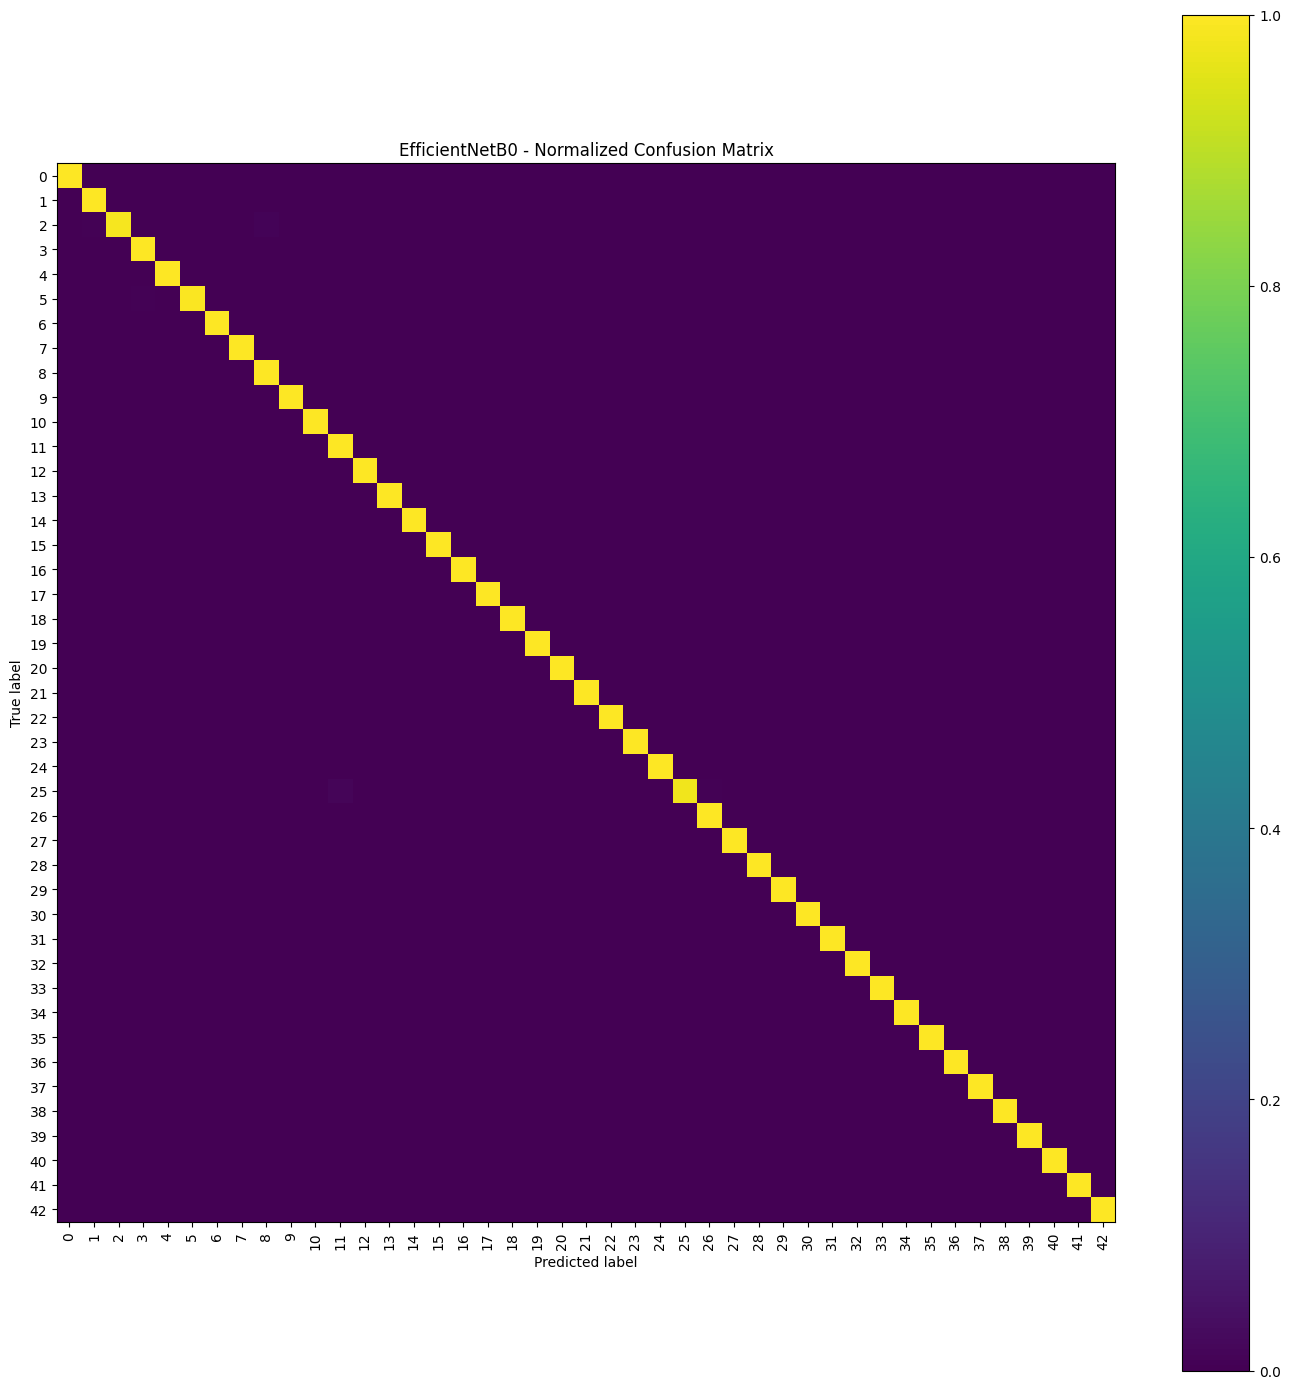

In [12]:
# Test-set predictions, metrics and the confusion matrix (saved as PNG)
y_true, y_pred = get_predictions(model, test_loader, device)

metrics = calculate_metrics(y_true, y_pred)

print(metrics)

plot_confusion_matrix(
    y_true,
    y_pred,
    model_name="EfficientNetB0",
    save_dir=FIGURES_DIR
)

In [13]:
# Per-class precision, recall and F1, saved together with the raw confusion matrix
report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
print_classification_report(y_true, y_pred)

with (METRICS_DIR / "efficientnetb0_classification_report.json").open("w", encoding="utf-8") as report_file:
    json.dump(report, report_file, indent=2)
np.savetxt(
    METRICS_DIR / "efficientnetb0_confusion_matrix.csv",
    confusion_matrix(y_true, y_pred, labels=list(range(43))),
    fmt="%d",
    delimiter=","
)

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        19
           1     0.9955    1.0000    0.9978       223
           2     1.0000    0.9871    0.9935       233
           3     0.9933    1.0000    0.9966       148
           4     1.0000    1.0000    1.0000       221
           5     1.0000    0.9952    0.9976       209
           6     1.0000    1.0000    1.0000        47
           7     1.0000    1.0000    1.0000       155
           8     0.9863    1.0000    0.9931       144
           9     1.0000    1.0000    1.0000       155
          10     1.0000    1.0000    1.0000       197
          11     0.9858    1.0000    0.9929       139
          12     1.0000    1.0000    1.0000       213
          13     1.0000    1.0000    1.0000       213
          14     1.0000    1.0000    1.0000        78
          15     1.0000    1.0000    1.0000        82
          16     1.0000    1.0000    1.0000        34
          17     1.0000    

## 5. Edge-deployment measurements

In [14]:
# Size and speed, measured with the same functions as Models A and B
average_epoch_time = float(np.mean(history["epoch_time"]))

estimated_size_kb = estimated_fp32_size_kb(model)
actual_size_kb = save_model_and_get_size(model, CHECKPOINT_DIR / "efficientnetb0_final.pth")

inference_time = measure_inference_time(model, test_loader, device)

print("Parameters:", parameters_total)
print("MACs per image:", macs)
print(f"Estimated FP32 size: {estimated_size_kb / 1024:.2f} MB")
print(f"Size on disk:        {actual_size_kb / 1024:.2f} MB")
print(f"Average epoch time:  {average_epoch_time:.2f} s")
print(f"Inference time:      {inference_time:.3f} ms/image")

Parameters: 4062631
MACs per image: 32021632
Estimated FP32 size: 15.50 MB
Size on disk:        15.79 MB
Average epoch time:  67.18 s
Inference time:      0.671 ms/image


In [15]:
# One row of results, read by the comparison notebook
results = {
    "Model": "EfficientNetB0",
    "Parameters": parameters_total,
    "MACs per Image": macs,
    "Estimated FP32 Size (MB)": estimated_size_kb / 1024,
    "Model Size (MB)": actual_size_kb / 1024,
    "Average Epoch Time (s)": average_epoch_time,
    "Inference Time (ms/image)": inference_time,
    "Test Accuracy": metrics["Test Accuracy"],
    "Macro Precision": metrics["Macro Precision"],
    "Macro Recall": metrics["Macro Recall"]
}

results_df = pd.DataFrame([results])

results_df.to_csv(METRICS_DIR / "efficientnetb0_metrics.csv", index=False)

results_df

,Model,Parameters,MACs per Image,Estimated FP32 Size (MB),Model Size (MB),Average Epoch Time (s),Inference Time (ms/image),Test Accuracy,Macro Precision,Macro Recall
0,EfficientNetB0,4062631,32021632,15.497707,15.786809,67.178107,0.670844,0.998248,0.998728,0.999118
